In [1]:
import os
import sys
import random
import time
from datetime import datetime
from dataclasses import dataclass
import pickle as pkl
from tracemalloc import start
from IPython.display import clear_output

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.tensorboard.writer import SummaryWriter

import gymnasium as gym
import pettingzoo
from stable_baselines3.common.buffers import ReplayBuffer

from mimopy import AntennaArray, Network
from mimopy.channels import LoS, Rician, SphericalWave

from maenv import MIMOMAEnv
from masac_agent import FCActor, SoftQNet, Agent
from masac_training import SAC_Args
from env_setup import *

%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = 'retina'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
args = SAC_Args()

args.exp_name = 'tx_sw'

args.tx_power = 28
args.rx_power = 8
args.ul_power = 8
args.dl_power = 8

args.Nt = 8
args.Nr = 8
args.Nul = 1
args.Ndl = 1

args.rx_coord = (0, 0, 0)
args.tx_coord = (100, -100, 0)
args.ul_coord = (5000, 5000, 0)
K = 50

In [3]:
tx = AntennaArray.ula(args.Nt, name="tx", array_center=args.tx_coord)
rx = AntennaArray.ula(args.Nr, name="rx", array_center=args.rx_coord)
ul = AntennaArray.ula(args.Nul, name="ul", array_center=args.ul_coord)
tx.power = args.tx_power
rx.power = args.rx_power
ul.power = args.ul_power
l = LoS(ul, rx, "ul-rx").realize()
si = Rician(tx, rx, K=50, name="si", nearfield=True).realize()
net = Network("DL with Interference")
net.add_links([l, si])
net.add_target_links([l])
net.add_target_nodes([rx])

env = MIMOMAEnv(net, args.target_meas, args.metrics)
env.reset(args.seed)

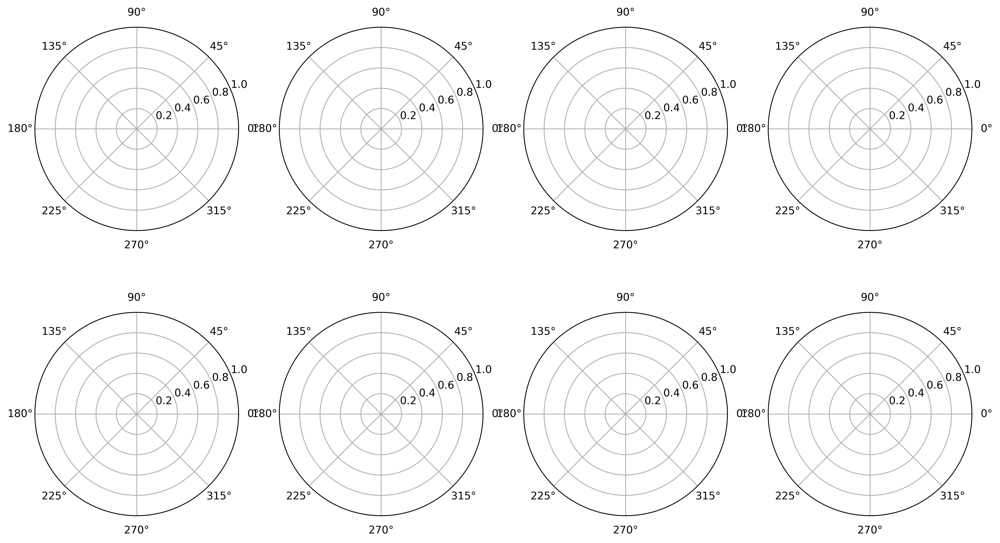

In [104]:
file_dir = "runs/DL/masac/20240321_1732_1_0db/env.pkl"
with open(file_dir, 'rb') as f:
    env = pkl.load(f)

fig, axes = plt.subplots(2, 4, figsize=(16, 9), dpi=300, subplot_kw={"projection": "polar"})


In [105]:
# root_dir = "runs/int_null_8x8/sw_tx-power-20db"
root_dir = "runs/int_null_8x8/sw_seed0"
env_paths = []
for root, dirs, files in os.walk(f"{root_dir}"):
    for file in files:
        if file == "env.pkl":
            env_paths.append(root)

Ks = [-50, -20, -10, 0, 10, 20, 50]

sinrs_bf = []
interferences_bf = []

sinrs_rl = []
interferences_rl = []

fig, axes = plt.subplots(2, 4, figsize=(16, 9), dpi=300, subplot_kw={"projection": "polar"})

# angles = np.linspace(-90, 120, 720)
angles = np.linspace(-180, 180, 720)
for K, ax in zip(Ks, axes.flatten()):
    env_path = [path for path in env_paths if f"K={K}" in path]
    if env_path == []:
        continue
    else:
        env_path = env_path[0]

    with open(f"{env_path}/env.pkl", "rb") as f:
        env = pkl.load(f)
    net = env.net
    rx = net.nodes["rx"]
    tx = net.nodes["tx"]
    l = net.links["los"]
    si = net.links["si"]

    rx.set_weights(rx.conjugate_beamformer(45))
    sinr_bf = net.sinr(l)
    snr_bf = net.snr(l)
    interference_bf = net.interference(l)

    sinrs_bf.append(sinr_bf)
    interferences_bf.append(interference_bf)

    rx.set_weights(env.best_weights[0])
    sinr_rl = net.sinr(l)
    snr_rl = net.snr(l)
    interference_rl = net.interference(l)

    sinrs_rl.append(sinr_rl)
    interferences_rl.append(interference_rl)

    # ax = ax[0, 0]
    rx.plot_gain(True, angles=angles, ax=ax, label=f"K=: {K}db")
    ax.set_title(f"K={K}")

rx.plot_gain(True, angles=angles, weights=net.links["los"].H.conj(), ax=axes[1, 3])
axes[1, 3].set_title("Conjugate Beamforming")

plt.tight_layout()
plt.show()
fig.savefig("figs/-20db_bf_weights_var_K.eps", format="eps")

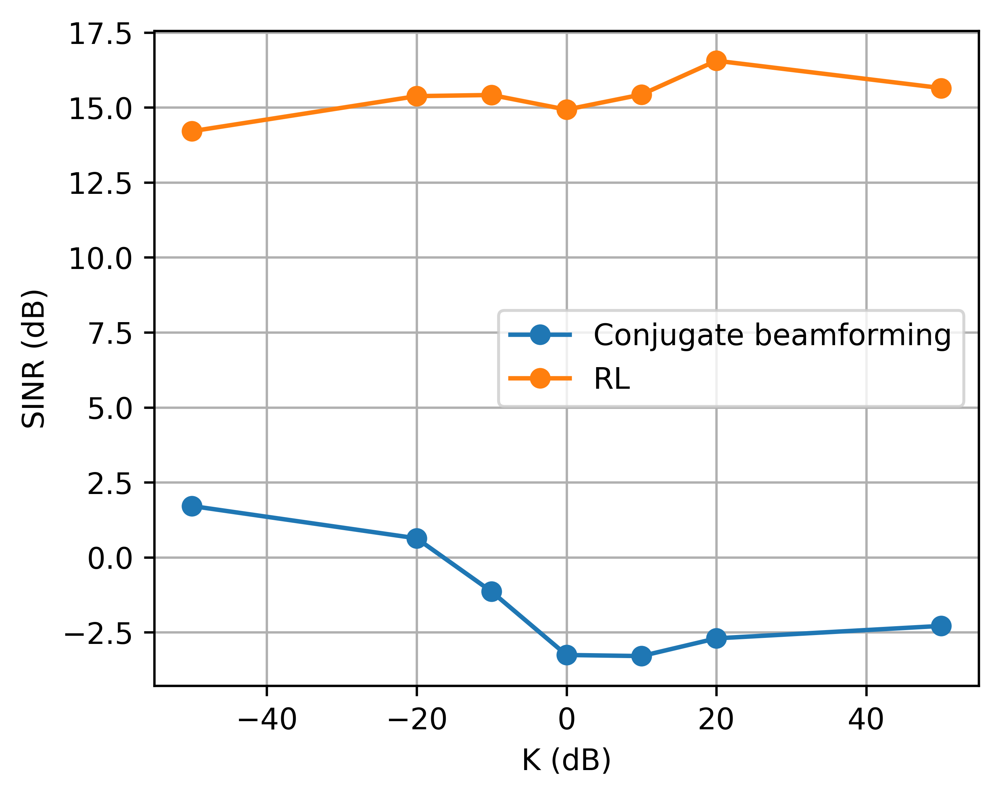

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


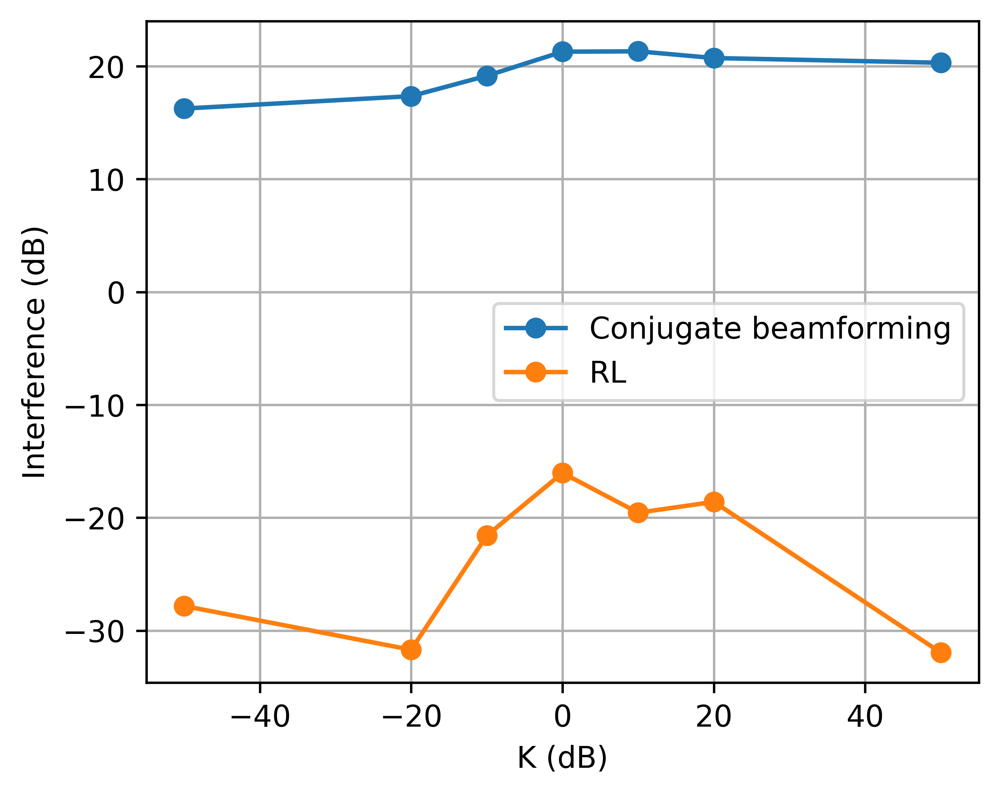

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


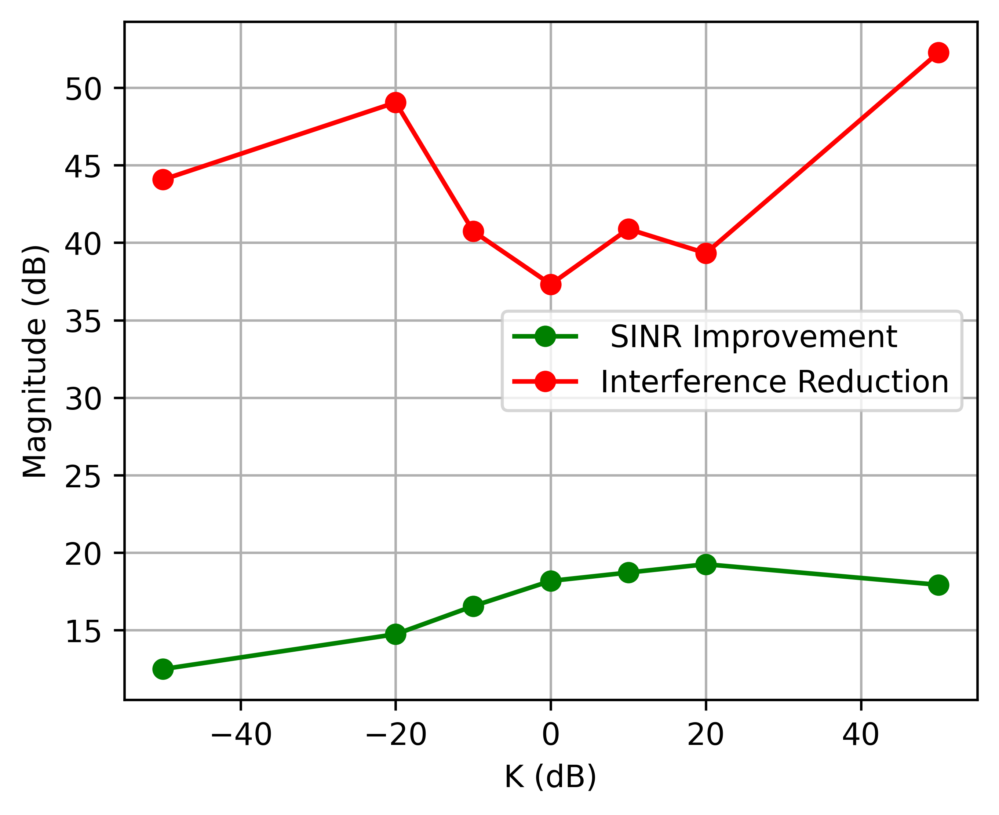

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


In [109]:
# root_dir = "runs/int_null_8x8/sw_tx-power-20db"
# root_dir = "runs/int_null_8x8/sw_seed0"
env_paths = []
for root, dirs, files in os.walk(f"{root_dir}"):
    for file in files:
        if file == "env.pkl":
            env_paths.append(root)
            
prefix = ""

fig, ax = plt.subplots(figsize=(5, 4), dpi=300)
ax.plot(Ks, sinrs_bf, "-o", label="Conjugate beamforming")
ax.plot(Ks, sinrs_rl, "-o", label="RL",)
ax.set_xlabel("K (dB)")
ax.set_ylabel("SINR (dB)")
ax.legend()
ax.grid()
plt.show()
fig.savefig(f"figs/{prefix}sinr_vs_K.eps", format="eps")


fig, ax = plt.subplots(figsize=(5, 4), dpi=300)
ax.plot(Ks, interferences_bf, "-o", label="Conjugate beamforming")
ax.plot(Ks, interferences_rl, "-o", label="RL")
ax.set_xlabel("K (dB)")
ax.set_ylabel("Interference (dB)")
ax.legend()
ax.grid()
plt.show()
fig.savefig(f"figs/{prefix}interference_vs_K.eps", format="eps")

fig, ax = plt.subplots(figsize=(5, 4), dpi=300)
ax.plot(Ks, np.array(sinrs_rl) - np.array(sinrs_bf), "-o", label=" SINR Improvement", color="green")
ax.plot(Ks, - np.array(interferences_rl) + np.array(interferences_bf), "-o", color="red", label="Interference Reduction")
ax.set_xlabel("K (dB)")
ax.set_ylabel("Magnitude (dB)")
ax.legend()
ax.grid()
plt.show()
fig.savefig(f"figs/{prefix}reduction.eps", format="eps")

==================== K=-50 ====================
RL: SINR: 14.21, SNR: 14.21, Interference: -27.82
BF: SINR: 1.71, SNR: 18.06, Interference: 16.25


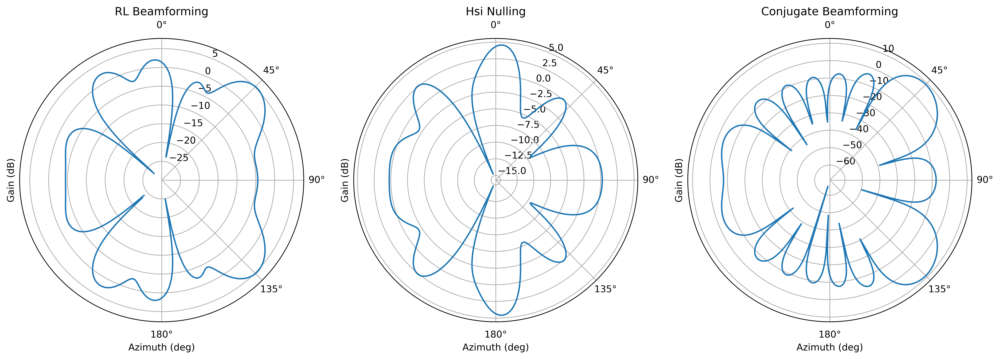

==================== K=-20 ====================
RL: SINR: 15.38, SNR: 15.38, Interference: -31.70
BF: SINR: 0.64, SNR: 18.06, Interference: 17.35


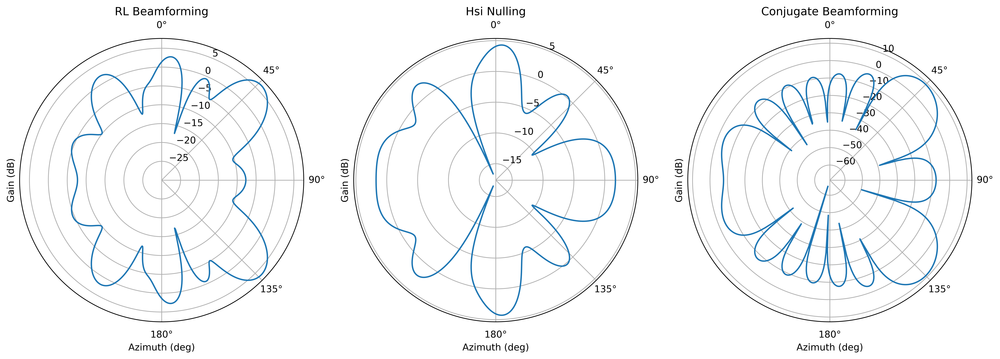

==================== K=-10 ====================
RL: SINR: 15.41, SNR: 15.44, Interference: -21.59
BF: SINR: -1.14, SNR: 18.06, Interference: 19.15


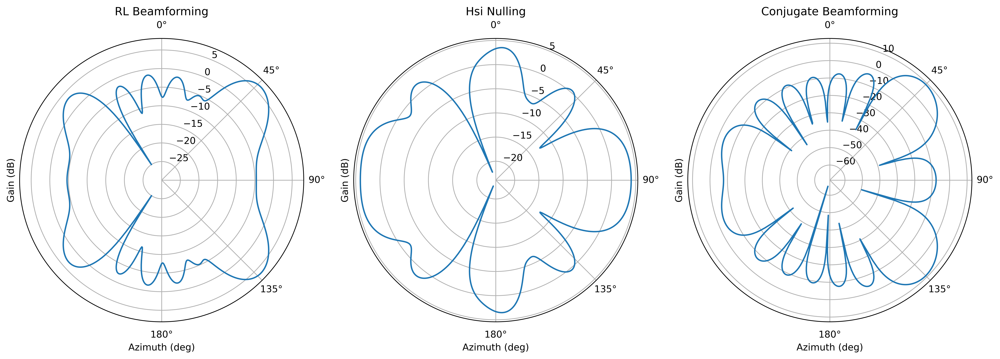

==================== K=0 ====================
RL: SINR: 14.93, SNR: 15.03, Interference: -16.04
BF: SINR: -3.25, SNR: 18.06, Interference: 21.28


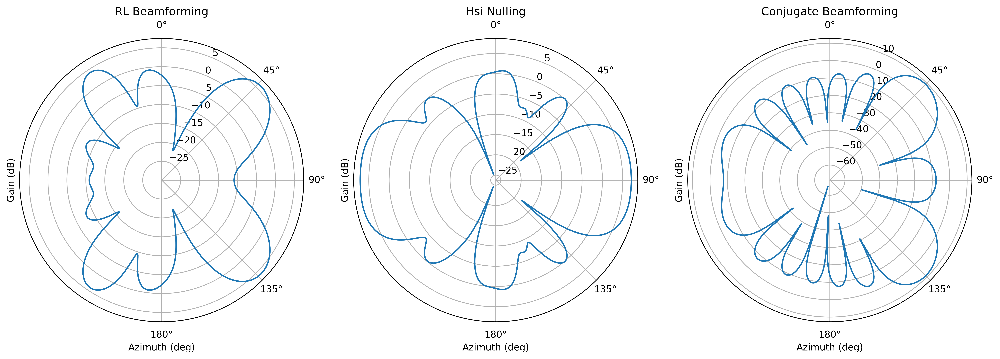

==================== K=10 ====================
RL: SINR: 15.43, SNR: 15.48, Interference: -19.56
BF: SINR: -3.29, SNR: 18.06, Interference: 21.32


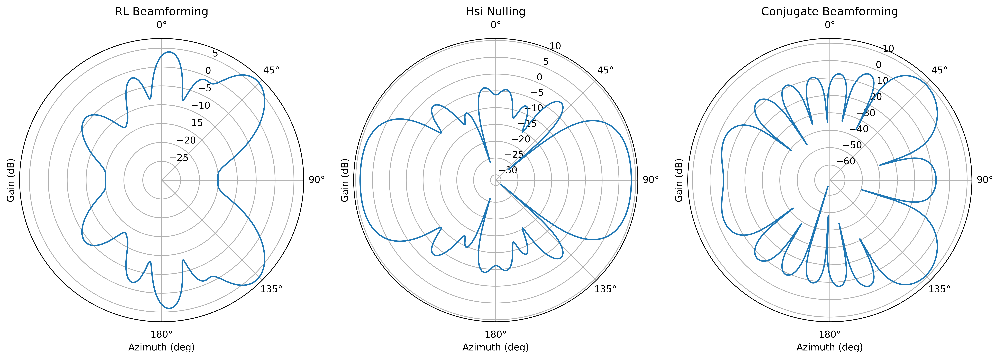

==================== K=20 ====================
RL: SINR: 16.56, SNR: 16.62, Interference: -18.60
BF: SINR: -2.70, SNR: 18.06, Interference: 20.72


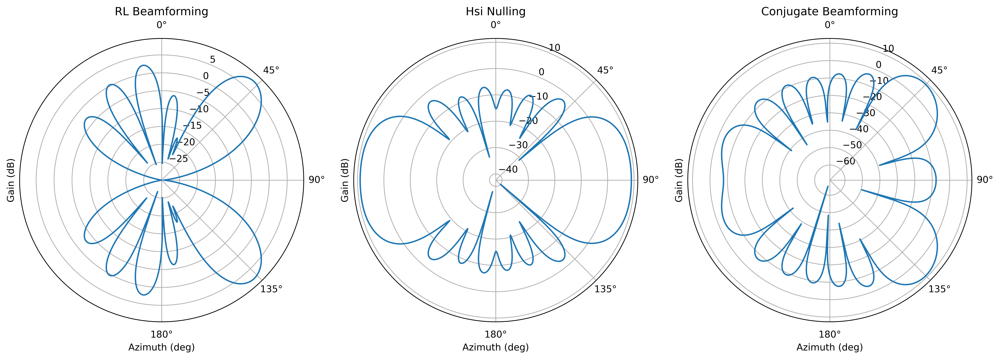

==================== K=50 ====================
RL: SINR: 15.65, SNR: 15.65, Interference: -31.96
BF: SINR: -2.28, SNR: 18.06, Interference: 20.31


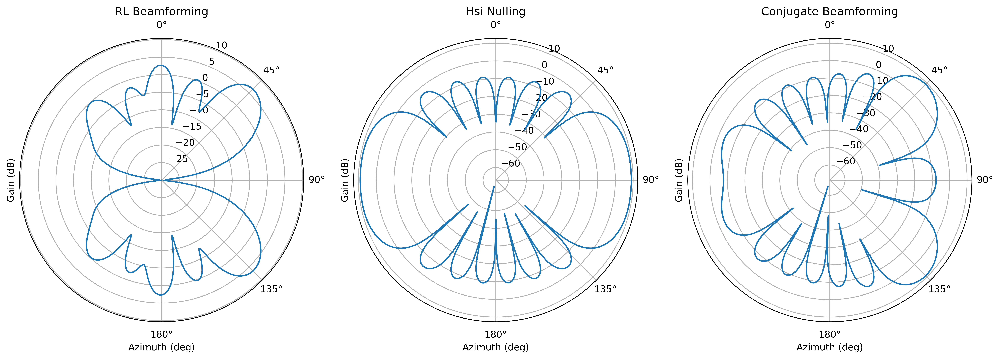

In [100]:
root_dir = "runs/int_null_8x8/sw_tx-power-20db"
root_dir = "runs/int_null_8x8/sw_seed0"
env_paths = []
for root, dirs, files in os.walk(f"{root_dir}"):
    for file in files:
        if file == "env.pkl":
            env_paths.append(root)

Ks = [-50, -20, -10, 0, 10, 20, 50]
# Ks = [50]

# angles = np.linspace(-90, 120, 720)
angles = np.linspace(-180, 180, 720)
for K in Ks:
    env_path = [path for path in env_paths if f"K={K}" in path]
    if env_path == []:
        continue
    else:
        env_path = env_path[0]

    with open(f"{env_path}/env.pkl", "rb") as f:
        env = pkl.load(f)
    net = env.net
    rx = net.nodes["rx"]
    tx = net.nodes["tx"]
    l = net.links["los"]
    si = net.links["si"]

    rx.set_weights(rx.conjugate_beamformer(45))
    sinr_bf = net.sinr(l)
    snr_bf = net.snr(l)
    interference_bf = net.interference(l)

    rx.set_weights(env.best_weights[0])
    sinr_rl = net.sinr(l)
    snr_rl = net.snr(l)
    interference_rl = net.interference(l)
    print(f"==================== K={K} ====================")
    print(
        f"RL: SINR: {sinr_rl:.2f}, SNR: {snr_rl:.2f}, Interference: {interference_rl:.2f}"
    )
    print(
        f"BF: SINR: {sinr_bf:.2f}, SNR: {snr_bf:.2f}, Interference: {interference_bf:.2f}"
    )
    fig = plt.figure(figsize=(15, 5), dpi=300)
    ax1 = plt.subplot(131, projection="polar")
    ax2 = plt.subplot(132, projection="polar")
    ax3 = plt.subplot(133, projection="polar")
    rx.plot_gain(True, angles=angles, ax=ax1)
    rx.plot_gain(True, angles=angles, weights=net.links["si"].H[0], ax=ax2)
    rx.plot_gain(True, angles=angles, weights=net.links["los"].H.conj(), ax=ax3)
    ax1.set_title("RL Beamforming")
    ax2.set_title("Hsi Nulling")
    ax3.set_title("Conjugate Beamforming")
    ax1.set_rlim(-30)
    plt.tight_layout()
    plt.show()

==================== K=-50 ====================
RL: SINR: 14.21, SNR: 14.21, Interference: -27.82
BF: SINR: 1.71, SNR: 18.06, Interference: 16.25


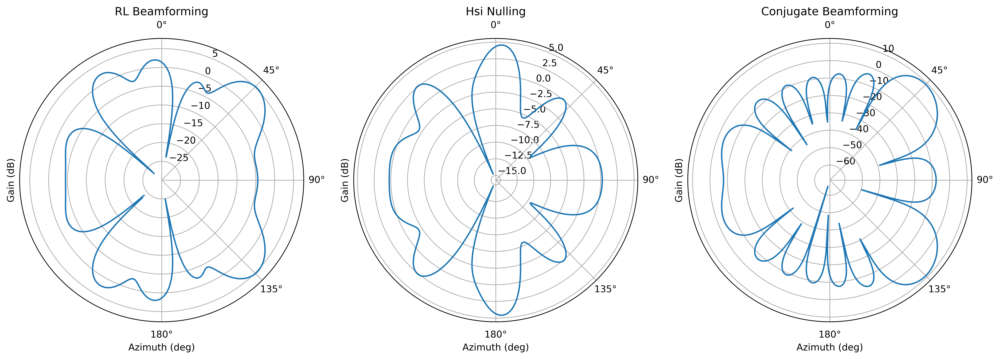

==================== K=-20 ====================
RL: SINR: 15.38, SNR: 15.38, Interference: -31.70
BF: SINR: 0.64, SNR: 18.06, Interference: 17.35


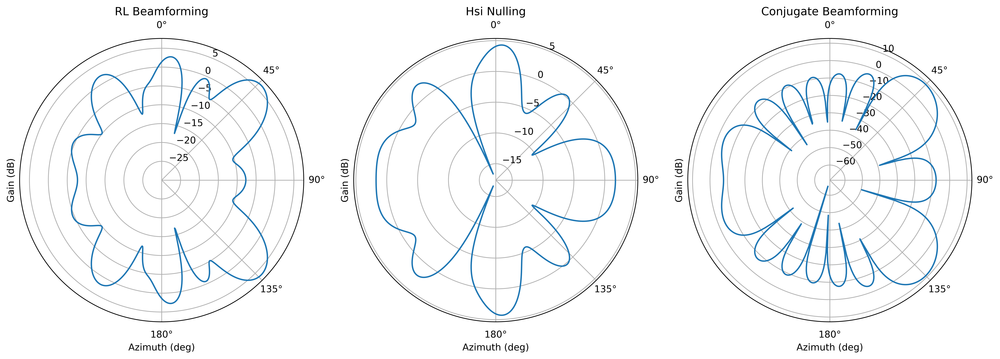

==================== K=-10 ====================
RL: SINR: 15.41, SNR: 15.44, Interference: -21.59
BF: SINR: -1.14, SNR: 18.06, Interference: 19.15


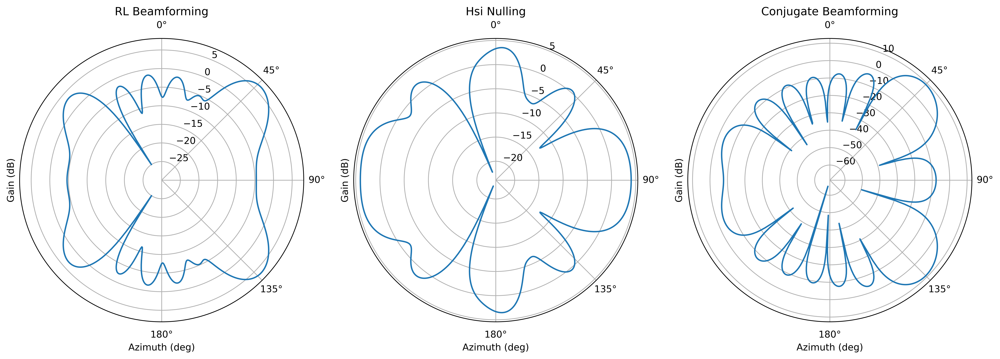

==================== K=0 ====================
RL: SINR: 14.93, SNR: 15.03, Interference: -16.04
BF: SINR: -3.25, SNR: 18.06, Interference: 21.28


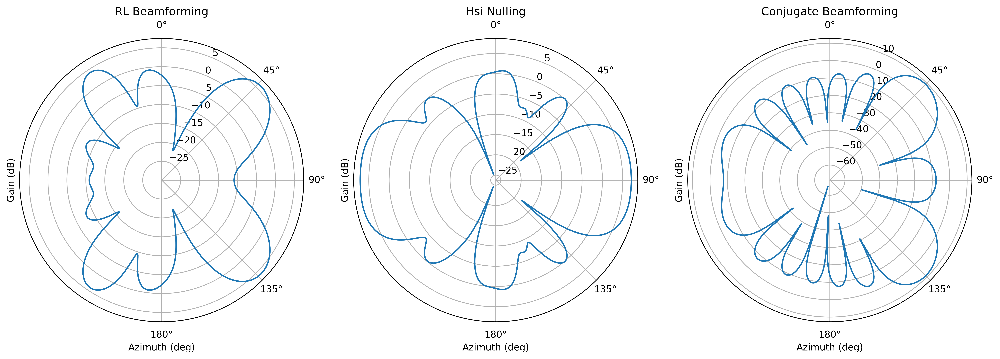

==================== K=10 ====================
RL: SINR: 15.43, SNR: 15.48, Interference: -19.56
BF: SINR: -3.29, SNR: 18.06, Interference: 21.32


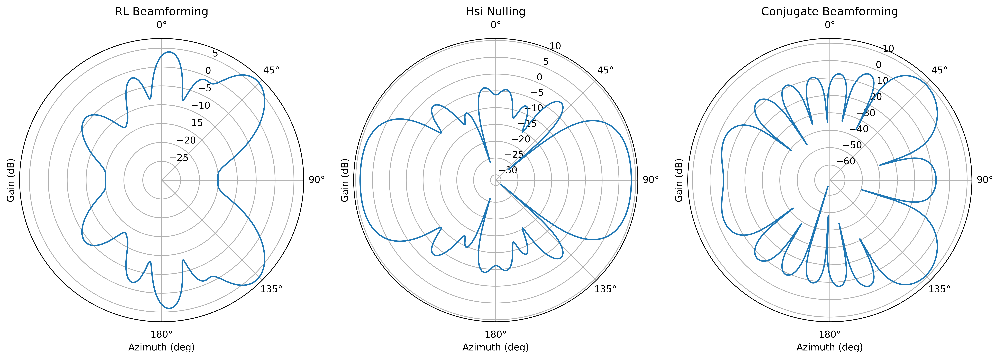

==================== K=20 ====================
RL: SINR: 16.56, SNR: 16.62, Interference: -18.60
BF: SINR: -2.70, SNR: 18.06, Interference: 20.72


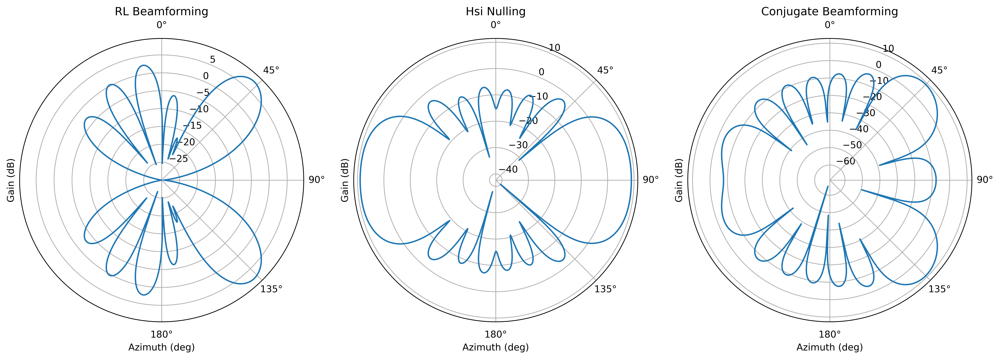

==================== K=50 ====================
RL: SINR: 15.65, SNR: 15.65, Interference: -31.96
BF: SINR: -2.28, SNR: 18.06, Interference: 20.31


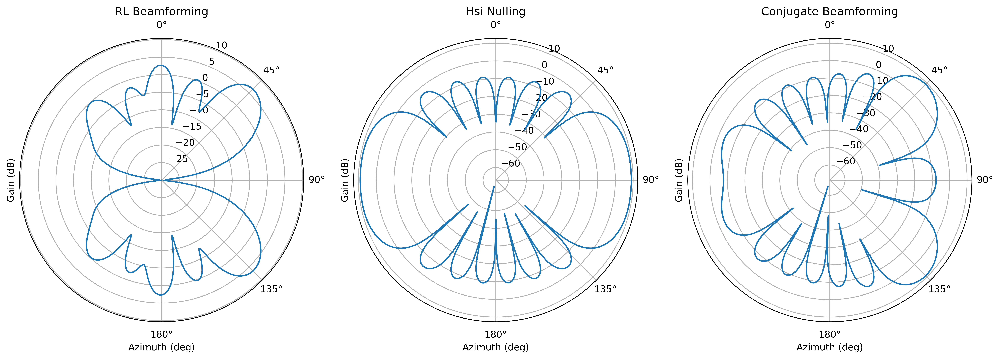

In [61]:
root_dir = "runs/int_null_8x8/sw_tx-power-20db"
root_dir = "runs/int_null_8x8/sw_seed0"
env_paths = []
for root, dirs, files in os.walk(f"{root_dir}"):
    for file in files:
        if file == "env.pkl":
            env_paths.append(root)

Ks = [-50, -20, -10, 0, 10, 20, 50]
# Ks = [50]

# angles = np.linspace(-90, 120, 720)
angles = np.linspace(-180, 180, 720)
for K in Ks:
    env_path = [path for path in env_paths if f"K={K}" in path]
    if env_path == []:
        continue
    else:
        env_path = env_path[0]

    with open(f"{env_path}/env.pkl", "rb") as f:
        env = pkl.load(f)
    net = env.net
    rx = net.nodes["rx"]
    tx = net.nodes["tx"]
    l = net.links["los"]
    si = net.links["si"]

    rx.set_weights(rx.conjugate_beamformer(45))
    sinr_bf = net.sinr(l)
    snr_bf = net.snr(l)
    interference_bf = net.interference(l)

    rx.set_weights(env.best_weights[0])
    sinr_rl = net.sinr(l)
    snr_rl = net.snr(l)
    interference_rl = net.interference(l)
    print(f"==================== K={K} ====================")
    print(
        f"RL: SINR: {sinr_rl:.2f}, SNR: {snr_rl:.2f}, Interference: {interference_rl:.2f}"
    )
    print(
        f"BF: SINR: {sinr_bf:.2f}, SNR: {snr_bf:.2f}, Interference: {interference_bf:.2f}"
    )
    fig = plt.figure(figsize=(15, 5), dpi=300)
    ax1 = plt.subplot(131, projection="polar")
    ax2 = plt.subplot(132, projection="polar")
    ax3 = plt.subplot(133, projection="polar")
    rx.plot_gain(True, angles=angles, ax=ax1)
    rx.plot_gain(True, angles=angles, weights=net.links["si"].H[0], ax=ax2)
    rx.plot_gain(True, angles=angles, weights=net.links["los"].H.conj(), ax=ax3)
    ax1.set_title("RL Beamforming")
    ax2.set_title("Hsi Nulling")
    ax3.set_title("Conjugate Beamforming")
    ax1.set_rlim(-30)
    plt.tight_layout()
    plt.show()

In [6]:
# Tensorboard writer
writer = SummaryWriter(run_dir)
writer.add_text(
    "hyperparameters",
    "|param|value|\n|-|-|\n%s"
    % ("\n".join([f"|{key}|{value}|" for key, value in vars(args).items()])),
)

start_time = time.time()
obs = env.observe(env.agent_selection)

for global_step, a in enumerate(env.agent_iter(args.total_timesteps)):
    agent = agents[a]
    # ALGO Logic
    if global_step < args.learning_starts:
        action = env.action_spaces[a].sample()
    else:
        action, _, _ = agent.actor.get_action(torch.Tensor(obs).to(args.device))
        action = action.detach().cpu().numpy()

    # Environment step
    env.step(action)
    next_obs, rewards, terminations, truncations, infos = env.last()
    real_next_obs = next_obs.copy()
    agent.rb.add(obs, next_obs, action, rewards, terminations, infos)

    # TODO: handle 'final observations' if needed

    obs = next_obs

    # Train the agent
    if global_step >= args.learning_starts:
        data = agent.rb.sample(args.batch_size)
        with torch.no_grad():
            next_state_action, next_state_log_pi, _ = agent.actor.get_action(
                data.next_observations
            )
            qf1_next_target = agent.qf1_target(
                data.next_observations, next_state_action
            )
            qf2_next_target = agent.qf2_target(
                data.next_observations, next_state_action
            )
            min_qf_next_target = (
                torch.min(qf1_next_target, qf2_next_target)
                - agent.alpha * next_state_log_pi
            )
            next_q_value = data.rewards.flatten() + (
                1 - data.dones.flatten()
            ) * args.gamma * (min_qf_next_target).view(-1)

        qf1_a_values = agent.qf1(data.observations, data.actions).view(-1)
        qf2_a_values = agent.qf2(data.observations, data.actions).view(-1)
        qf1_loss = F.mse_loss(qf1_a_values, next_q_value)
        qf2_loss = F.mse_loss(qf2_a_values, next_q_value)
        qf_loss = qf1_loss + qf2_loss

        agent.qf_optimizer.zero_grad()
        qf_loss.backward()
        agent.qf_optimizer.step()

        if (global_step - args.learning_starts - 1999) % 2000 == 0:
            env.reduce_action_space(0.7)
            print(
                f"Max amp/phase change reduced to {env.max_amp_change}, {env.max_phase_change * 180 / np.pi:.2f} deg"
            )

        # TD3 delayed policy updates
        if global_step % args.policy_frequency == 0:
            # compensate for the delay by doing 'actor_update_interval' instead of 1
            for _ in range(args.policy_frequency):
                pi, log_pi, _ = agent.actor.get_action(data.observations)
                qf1_pi = agent.qf1(data.observations, pi)
                qf2_pi = agent.qf2(data.observations, pi)
                min_qf_pi = torch.min(qf1_pi, qf2_pi)
                actor_loss = (agent.alpha * log_pi - min_qf_pi).mean()

                agent.actor_optimizer.zero_grad()
                actor_loss.backward()
                agent.actor_optimizer.step()

                if args.autotune:
                    with torch.no_grad():
                        _, log_pi, _ = agent.actor.get_action(data.observations)
                    alpha_loss = (
                        -agent.log_alpha.exp() * (log_pi + agent.target_entropy)
                    ).mean()

                    agent.alpha_optimizer.zero_grad()
                    alpha_loss.backward()
                    agent.alpha_optimizer.step()
                    agent.alpha = agent.log_alpha.exp().item()

        # Update target networks
        if global_step % args.target_network_frequency == 0:
            for param, target_param in zip(
                agent.qf1.parameters(), agent.qf1_target.parameters()
            ):
                target_param.data.copy_(
                    args.tau * param.data + (1 - args.tau) * target_param.data
                )
            for param, target_param in zip(
                agent.qf2.parameters(), agent.qf2_target.parameters()
            ):
                target_param.data.copy_(
                    args.tau * param.data + (1 - args.tau) * target_param.data
                )

        # Log losses to tensorboard
        if global_step % 51 == 0:
            # global_step = float(global_step)

            for a in env.agents:
                # Network related metrics
                for key in ("sinr", "spectral_efficiency", "gain"):
                    writer.add_scalar(
                        f"A{a} Current State/{key}",
                        env.state[key][a],
                        global_step,
                    )
                    writer.add_scalar(
                        f"A{a} Best State/{key}",
                        env.best_state[key][a],
                        global_step,
                    )
            # Agent related metrics
            a = env.agent_selection
            writer.add_scalar(
                f"A{a} Losses/alpha",
                agents[a].alpha,
                global_step,
            )
            if args.autotune:
                writer.add_scalar(
                    f"A{a} Losses/alpha loss",
                    alpha_loss.item(),
                    global_step,
                )
            writer.add_scalar(
                f"A{a} Losses/qf1_values",
                qf1_a_values.mean().item(),
                global_step,
            )
            writer.add_scalar(
                f"A{a} Losses/qf2_values",
                qf2_a_values.mean().item(),
                global_step,
            )
            writer.add_scalar(f"A{a} Losses/qf_loss", qf_loss.item() / 2.0, global_step)
            writer.add_scalar(f"A{a} Losses/actor_loss", actor_loss.item(), global_step)
            writer.add_scalar(f"A{a} Losses/rewards", rewards, global_step)
            writer.add_scalar(
                "SPS", global_step / (time.time() - start_time), global_step
            )

        if global_step % 500 == 0:
            with open(f"{run_dir}/env.pkl", "wb") as f:
                pkl.dump(env, f)
            if args.save_model:
                for a in env.agents:
                    agent = agents[a]
                    torch.save(
                        agent.actor.state_dict(),
                        f"{run_dir}/agent_{a}/actor_{global_step}.pth",
                    )
                    torch.save(
                        agent.qf1.state_dict(),
                        f"{run_dir}/agent_{a}/qf1_{global_step}.pth",
                    )
                    torch.save(
                        agent.qf2.state_dict(),
                        f"{run_dir}/agent_{a}/qf2_{global_step}.pth",
                    )

            print("==========================")
            print("Step:", global_step)
            print("SPS:", int(global_step / (time.time() - start_time)))
            print("Agent: ", env.agent_selection)
            print("Rewards:", rewards)
            print(
                f"Max amp/phase change: {env.max_amp_change}, {env.max_phase_change * 180 / np.pi:.2f} deg"
            )
            print(f"target {args.metrics}, {env.target_meas}")
            print(
                "Target dist:",
                np.asarray(env.target_meas) - np.asarray(env.state[env.metrics]),
            )
            print("-------Best State-------")
            for key in ["sinr", "spectral_efficiency", "gain"]:
                print(f"{key}:", env.best_state[key])
            print("-------Current State---------")
            for key in ["sinr", "spectral_efficiency", "gain"]:
                print(f"{key}:", env.state[key])

            # print("gain:", infos["gain"][0])
            plt.close("all")
            env.net.plot_gain(weights=env.best_weights)
            env.net.plot_gain()
            clear_output(wait=True)

KeyboardInterrupt: 

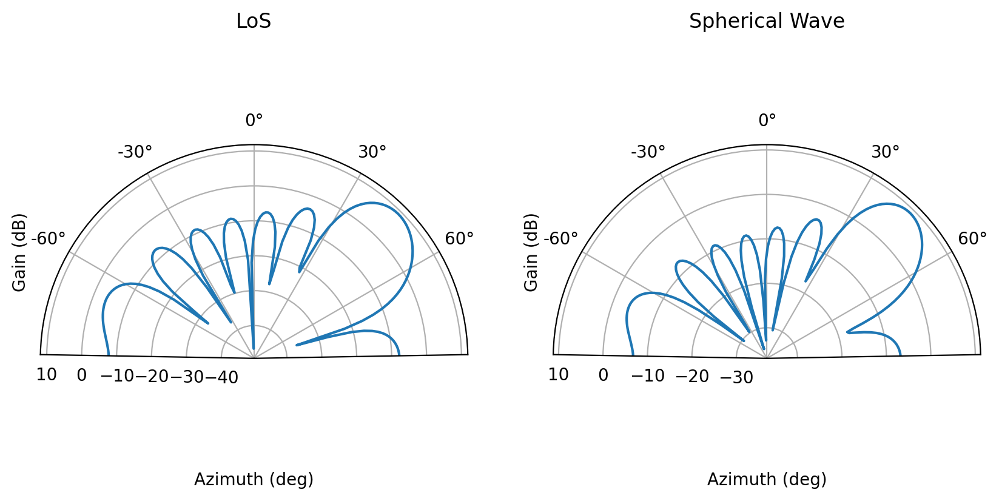

In [17]:
tx = AntennaArray.ula(2, name="tx", array_center=(20, 20, 0))
los = LoS(tx, rx, "los").realize()
sw = SphericalWave(tx, rx, "sw").realize()

fig, axes = plt.subplots(1, 2, figsize=(10, 5), subplot_kw=dict(polar=True))
rx.plot_gain(weights=los.H[:, 0], polar=True, ax=axes[0])
rx.plot_gain(weights=sw.H[:, 0], polar=True, ax=axes[1])
axes[0].set_title("LoS")
axes[1].set_title("Spherical Wave")
plt.show()